<a href="https://colab.research.google.com/github/Tharunika1030/pds/blob/main/Plant_Disease_Detection_Comparative_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# STEP 1: Check GPU and TensorFlow

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

if tf.config.list_physical_devices('GPU'):
    print("✅ GPU is ready!")
else:
    print("⚠️ GPU is not enabled. Go to Runtime → Change runtime type → T4 GPU.")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU is ready!


In [ ]:
!pip -q install kagglehub

import kagglehub
import os

print("KaggleHub installed successfully!")

KaggleHub installed successfully!


In [ ]:
!pip -q install tensorflow-datasets


In [ ]:
import tensorflow_datasets as tfds

print("TensorFlow Datasets is ready!")

TensorFlow Datasets is ready!


In [ ]:
# STEP 4A - Check TensorFlow Datasets

import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow version:", tf.__version__)
print("TFDS imported successfully!")
print("tfds.load available:", hasattr(tfds, "load"))

TensorFlow version: 2.20.0
TFDS imported successfully!
tfds.load available: True


In [ ]:
!pip uninstall -y tensorflow-datasets
!pip install -q tensorflow-datasets
print("TFDS installation completed.")

Found existing installation: tensorflow-datasets 4.9.10
Uninstalling tensorflow-datasets-4.9.10:
  Successfully uninstalled tensorflow-datasets-4.9.10
TFDS installation completed.


In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow version:", tf.__version__)
print("TFDS imported successfully!")
print("tfds.load available:", hasattr(tfds, "load"))
print("TFDS location:", tfds.__file__)

TensorFlow version: 2.20.0
TFDS imported successfully!
tfds.load available: True
TFDS location: /usr/local/lib/python3.13/dist-packages/tensorflow_datasets/__init__.py


In [ ]:
!pip install -q --upgrade "protobuf>=6.31.1,<7"
print("Protobuf fixed.")

Protobuf fixed.


In [ ]:
print("Runtime restarted successfully!")

Runtime restarted successfully!


In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow version:", tf.__version__)
print("TFDS imported successfully!")
print("tfds.load available:", hasattr(tfds, "load"))

TensorFlow version: 2.20.0
TFDS imported successfully!
tfds.load available: True


In [ ]:
import tensorflow_datasets as tfds

(ds_train, ds_test), ds_info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

print("PlantVillage loaded successfully!")
print("Training samples:", ds_info.splits["train"].num_examples * 0.8)
print("Number of classes:", ds_info.features["label"].num_classes)
print("Classes:", ds_info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

DownloadError: Failed to get url https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/file_downloaded. HTTP code: 403.

In [ ]:
!pip install -q importlib_resources
print("importlib_resources installed successfully!")

importlib_resources installed successfully!


In [ ]:
import tensorflow_datasets as tfds

(ds_train, ds_test), ds_info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

print("PlantVillage loaded successfully!")
print("Total images:", ds_info.splits["train"].num_examples)
print("Number of classes:", ds_info.features["label"].num_classes)
print("Classes:", ds_info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

DownloadError: Failed to get url https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/file_downloaded. HTTP code: 403.

In [ ]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download("emmarex/plantdisease")

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/plantdisease


In [ ]:
import os

dataset_path = "/kaggle/input/plantdisease"

print("Dataset path:", dataset_path)
print("\nFiles and folders:")

for item in os.listdir(dataset_path):
    print(item)

Dataset path: /kaggle/input/plantdisease

Files and folders:
PlantVillage
plantvillage


In [ ]:
import os

plantvillage_path = "/kaggle/input/plantdisease/PlantVillage"

print("PlantVillage contents:")

for item in os.listdir(plantvillage_path):
    print(item)

PlantVillage contents:
Pepper__bell___Bacterial_spot
Potato___healthy
Tomato_Leaf_Mold
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato_Bacterial_spot
Tomato_Septoria_leaf_spot
Tomato_healthy
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato_Early_blight
Tomato__Target_Spot
Pepper__bell___healthy
Potato___Late_blight
Tomato_Late_blight
Potato___Early_blight
Tomato__Tomato_mosaic_virus


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = "/kaggle/input/plantdisease/PlantVillage"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("\nDataset preparation completed!")
print("Number of classes:", train_data.num_classes)
print("Class names:")
print(list(train_data.class_indices.keys()))

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.

Dataset preparation completed!
Number of classes: 15
Class names:
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


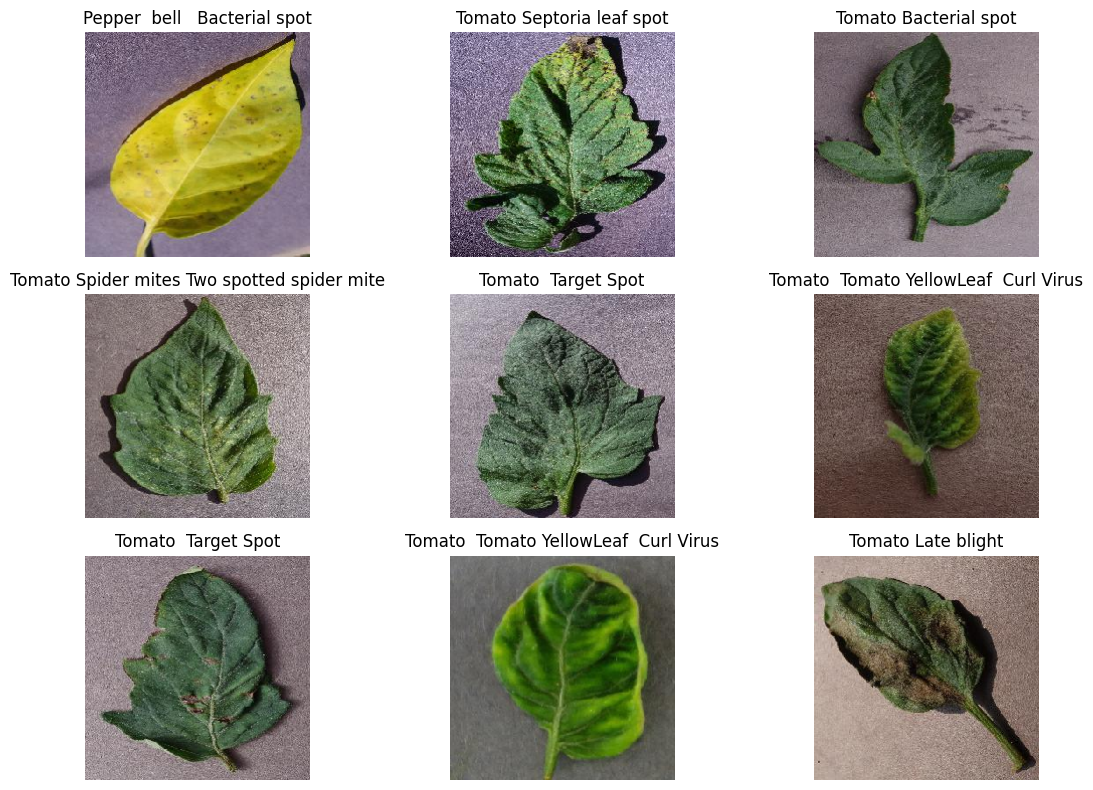

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(train_data)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i])

    class_index = labels[i].argmax()
    class_name = list(train_data.class_indices.keys())[class_index]

    plt.title(class_name.replace("_", " "))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(15, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,895 (42.61 MB)

 Trainable params: 11,170,895 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import time

start_time = time.time()

cnn_history = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

cnn_training_time = time.time() - start_time

print("\nCNN training completed!")
print("Training time: {:.2f} seconds".format(cnn_training_time))

Epoch 1/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 125s 222ms/step - accuracy: 0.5275 - loss: 1.4751 - val_accuracy: 0.7637 - val_loss: 0.7098
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 47s 90ms/step - accuracy: 0.7177 - loss: 0.8555 - val_accuracy: 0.8219 - val_loss: 0.5501
Epoch 3/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 46s 89ms/step - accuracy: 0.7835 - loss: 0.6496 - val_accuracy: 0.8656 - val_loss: 0.4161
Epoch 4/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 48s 93ms/step - accuracy: 0.8168 - loss: 0.5398 - val_accuracy: 0.8634 - val_loss: 0.4134
Epoch 5/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 49s 95ms/step - accuracy: 0.8529 - loss: 0.4332 - val_accuracy: 0.8816 - val_loss: 0.3411
Epoch 6/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - accuracy: 0.8807 - loss: 0.3575 - val_accuracy: 0.8886 - val_loss: 0.3385
Epoch 7/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 46s 88ms/step - accuracy: 0.8927 - loss: 0.3107 - val_accuracy: 0.9081 - val_loss: 0.2923
Epoch 8/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 45s 86ms/step - accuracy: 0.9095 - loss: 0.2658 

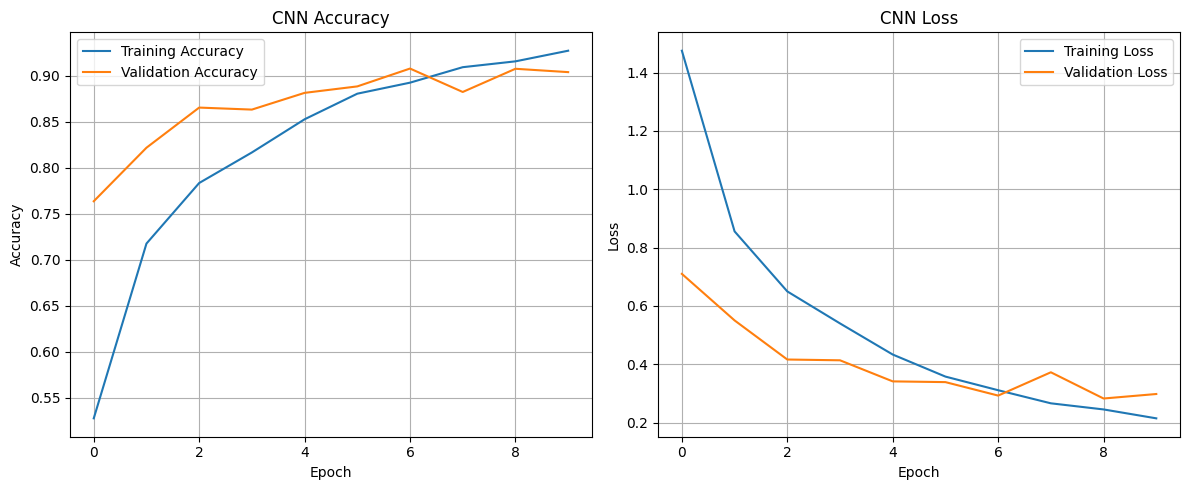

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step

===== CNN PERFORMANCE =====
Accuracy : 0.9042
Precision: 0.9069
Recall   : 0.9042
F1 Score : 0.9023

===== CLASSIFICATION REPORT =====
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.95      0.90      0.93       199
                     Pepper__bell___healthy       0.95      0.97      0.96       295
                      Potato___Early_blight       0.93      0.97      0.95       200
                       Potato___Late_blight       0.77      0.96      0.86       200
                           Potato___healthy       0.74      0.77      0.75        30
                      Tomato_Bacterial_spot       0.85      1.00      0.92       425
                        Tomato_Early_blight       0.84      0.55      0.66       200
                         Tomato_Late_blight       0.87      0.83      0.85       381
                           Tomato_Leaf_Mold       0.83  

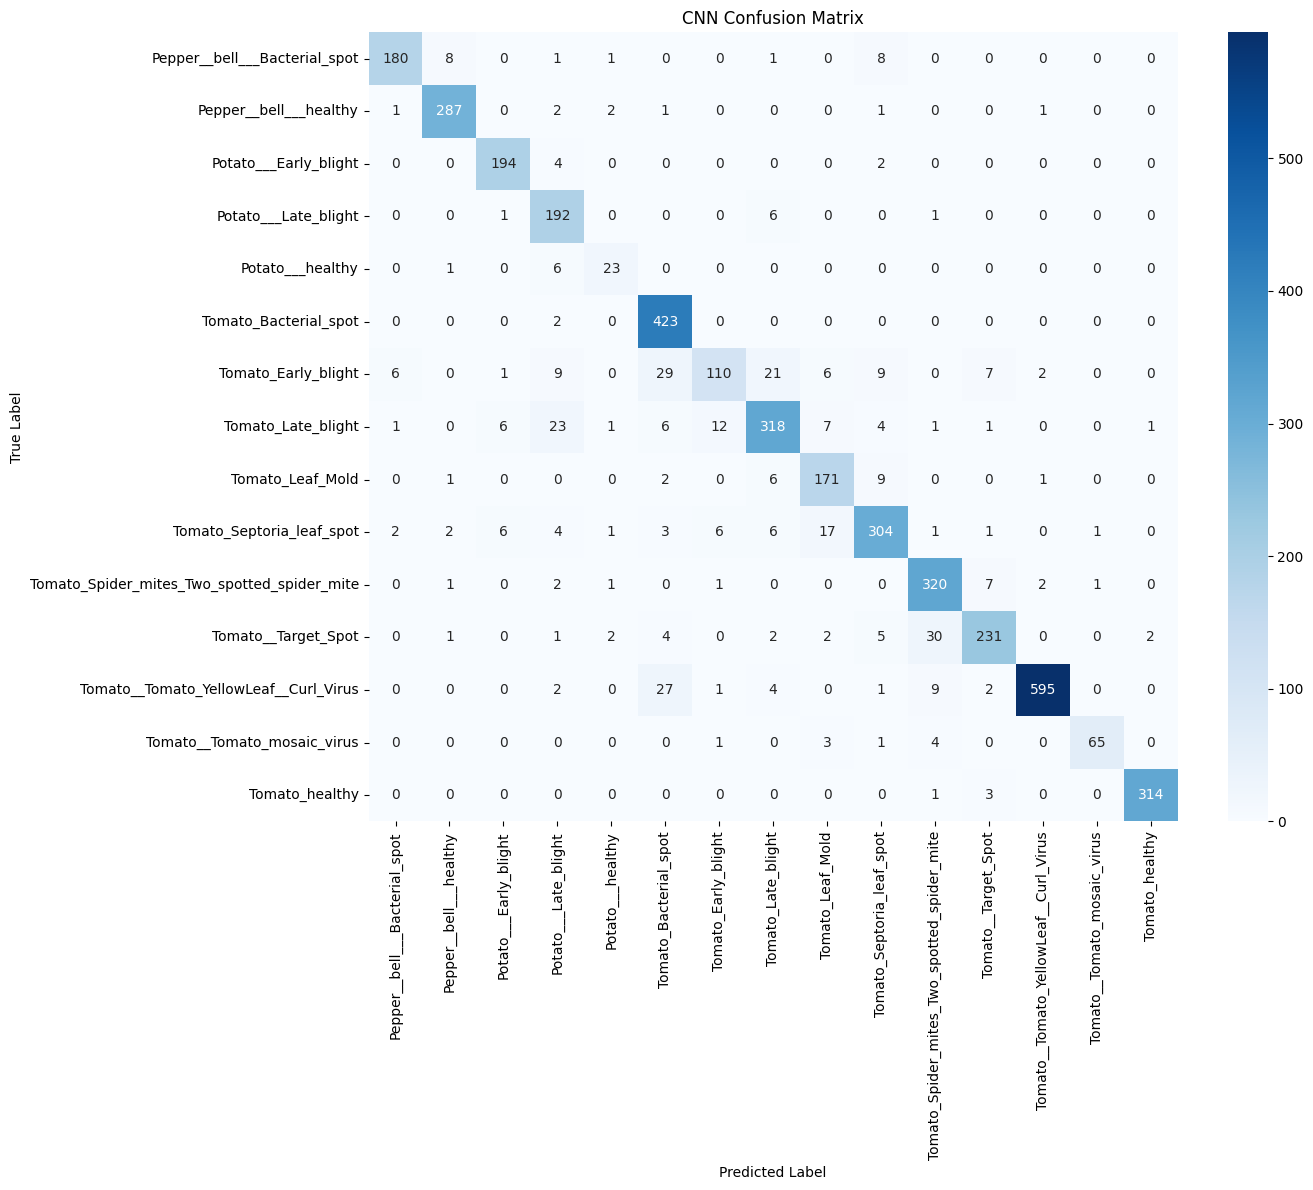

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Reset validation generator
val_data.reset()

# Predict all validation images
predictions = cnn_model.predict(val_data, verbose=1)

y_pred = np.argmax(predictions, axis=1)
y_true = val_data.classes

class_names = list(val_data.class_indices.keys())

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("\n===== CNN PERFORMANCE =====")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

dataset_path = "/kaggle/input/plantdisease/PlantVillage"

resnet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

resnet_train_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

resnet_val_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("ResNet50 data preparation completed!")
print("Number of classes:", resnet_train_data.num_classes)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
ResNet50 data preparation completed!
Number of classes: 15


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

# Load pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classifier
resnet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(15, activation="softmax")
])

resnet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,919 (90.99 MB)

 Trainable params: 264,207 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
import time

start_time = time.time()

resnet_history = resnet_model.fit(
    resnet_train_data,
    validation_data=resnet_val_data,
    epochs=5
)

resnet_training_time = time.time() - start_time

print("\nResNet50 training completed!")
print("Training time: {:.2f} seconds".format(resnet_training_time))

Epoch 1/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 97s 165ms/step - accuracy: 0.7539 - loss: 0.7771 - val_accuracy: 0.9326 - val_loss: 0.2359
Epoch 2/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 75s 144ms/step - accuracy: 0.8767 - loss: 0.3677 - val_accuracy: 0.9444 - val_loss: 0.1765
Epoch 3/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 75s 145ms/step - accuracy: 0.9054 - loss: 0.2845 - val_accuracy: 0.9612 - val_loss: 0.1259
Epoch 4/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 82s 158ms/step - accuracy: 0.9177 - loss: 0.2461 - val_accuracy: 0.9498 - val_loss: 0.1492
Epoch 5/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 76s 148ms/step - accuracy: 0.9193 - loss: 0.2354 - val_accuracy: 0.9624 - val_loss: 0.1158

ResNet50 training completed!
Training time: 405.46 seconds


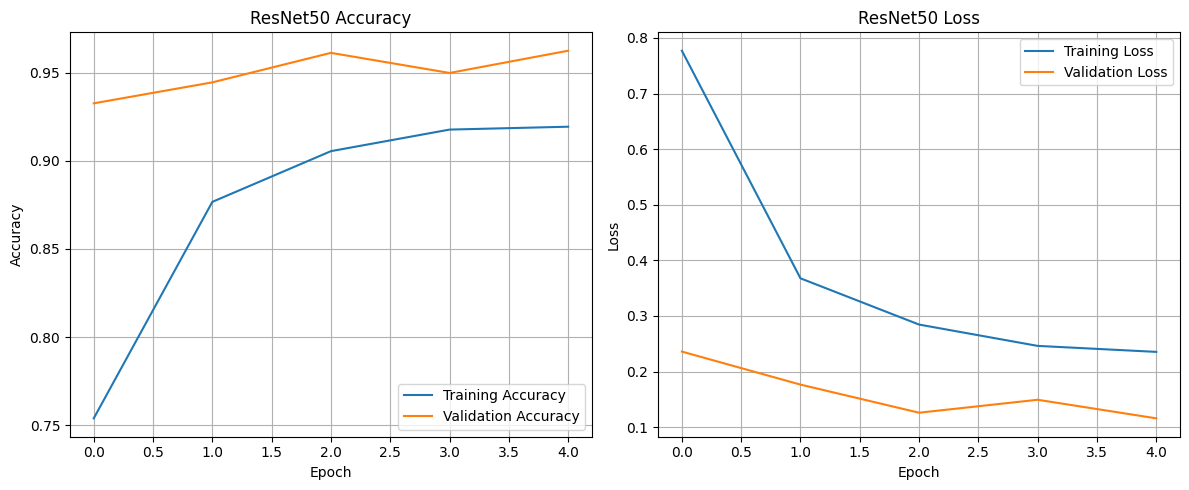

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(resnet_history.history["accuracy"], label="Training Accuracy")
plt.plot(resnet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(resnet_history.history["loss"], label="Training Loss")
plt.plot(resnet_history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

129/129 ━━━━━━━━━━━━━━━━━━━━ 24s 143ms/step

===== RESNET50 PERFORMANCE =====
Accuracy : 0.9624
Precision: 0.9631
Recall   : 0.9624
F1 Score : 0.9617

===== CLASSIFICATION REPORT =====
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.98      0.99      0.99       199
                     Pepper__bell___healthy       1.00      0.98      0.99       295
                      Potato___Early_blight       0.99      1.00      0.99       200
                       Potato___Late_blight       0.96      0.99      0.97       200
                           Potato___healthy       0.96      0.90      0.93        30
                      Tomato_Bacterial_spot       0.95      1.00      0.97       425
                        Tomato_Early_blight       0.99      0.74      0.85       200
                         Tomato_Late_blight       0.95      0.97      0.96       381
                           Tomato_Leaf_Mold      

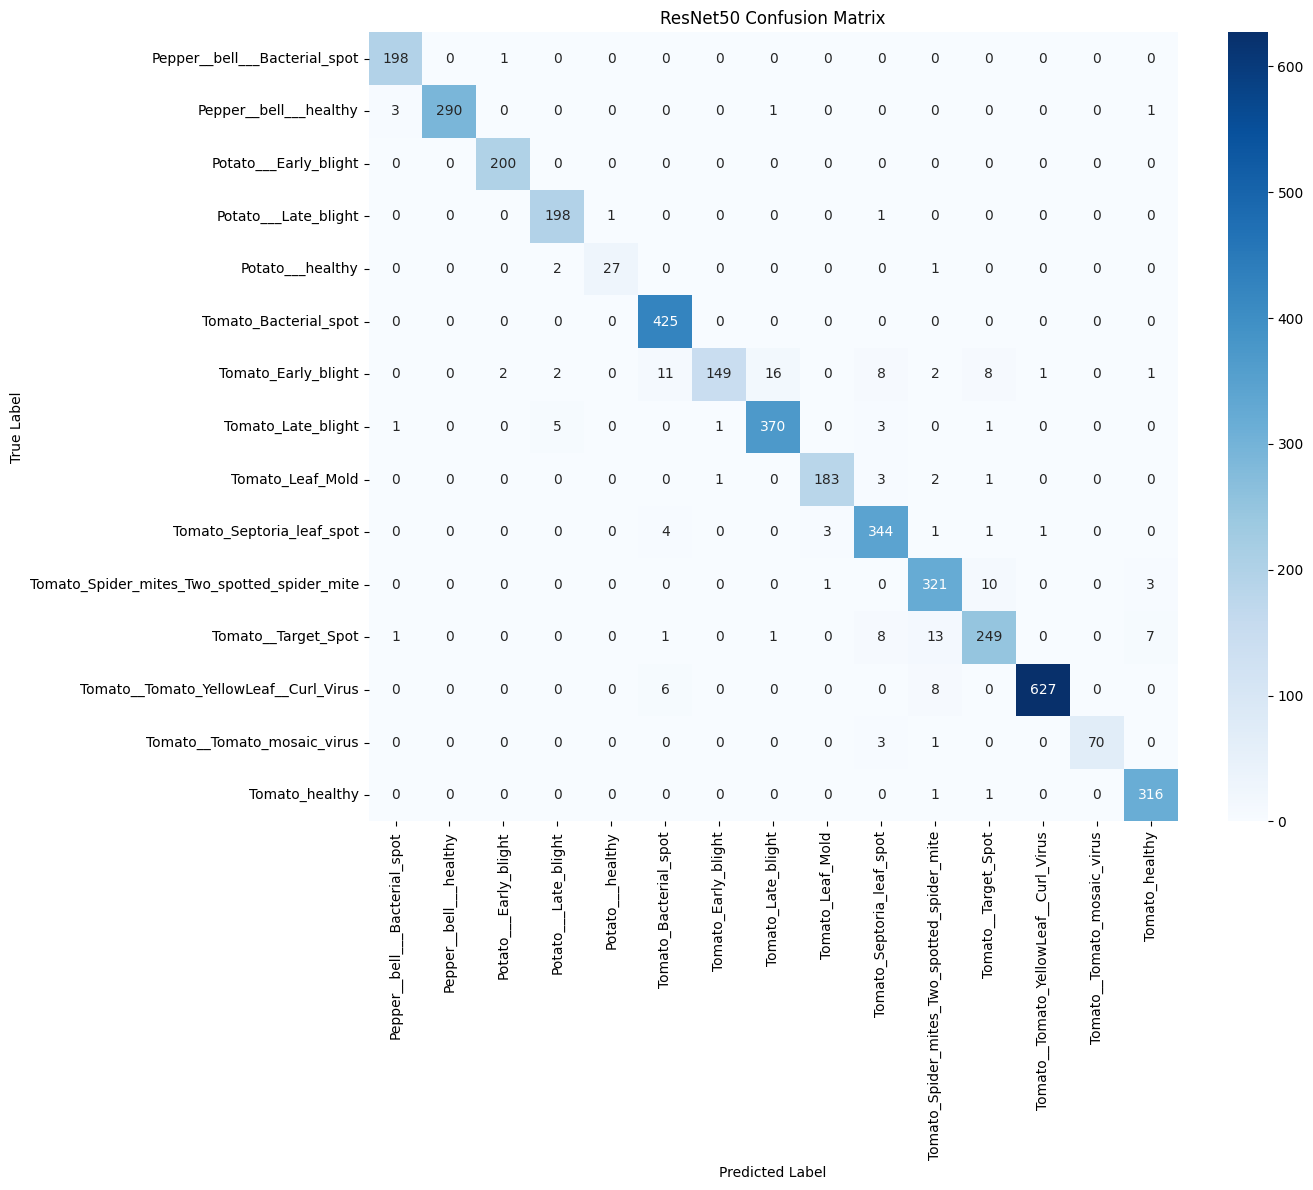

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# Reset validation generator
resnet_val_data.reset()

# Predictions
resnet_predictions = resnet_model.predict(resnet_val_data, verbose=1)

resnet_y_pred = np.argmax(resnet_predictions, axis=1)
resnet_y_true = resnet_val_data.classes

class_names = list(resnet_val_data.class_indices.keys())

# Metrics
resnet_accuracy = accuracy_score(resnet_y_true, resnet_y_pred)
resnet_precision = precision_score(
    resnet_y_true, resnet_y_pred,
    average="weighted",
    zero_division=0
)
resnet_recall = recall_score(
    resnet_y_true, resnet_y_pred,
    average="weighted",
    zero_division=0
)
resnet_f1 = f1_score(
    resnet_y_true, resnet_y_pred,
    average="weighted",
    zero_division=0
)

print("\n===== RESNET50 PERFORMANCE =====")
print("Accuracy :", round(resnet_accuracy, 4))
print("Precision:", round(resnet_precision, 4))
print("Recall   :", round(resnet_recall, 4))
print("F1 Score :", round(resnet_f1, 4))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    resnet_y_true,
    resnet_y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm_resnet = confusion_matrix(
    resnet_y_true,
    resnet_y_pred
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

dataset_path = "/kaggle/input/plantdisease/PlantVillage"

mobilenet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

mobilenet_train_data = mobilenet_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

mobilenet_val_data = mobilenet_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("MobileNetV2 data preparation completed!")
print("Training images:", mobilenet_train_data.samples)
print("Validation images:", mobilenet_val_data.samples)
print("Number of classes:", mobilenet_train_data.num_classes)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
MobileNetV2 data preparation completed!
Training images: 16516
Validation images: 4122
Number of classes: 15


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_mobilenet = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_mobilenet.trainable = False

# Build classifier
mobilenet_model = models.Sequential([
    base_mobilenet,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(15, activation="softmax")
])

mobilenet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,887 (9.25 MB)

 Trainable params: 165,903 (648.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import time

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    mobilenet_train_data,
    validation_data=mobilenet_val_data,
    epochs=5
)

mobilenet_training_time = time.time() - start_time

print("\nMobileNetV2 training completed!")
print("Training time: {:.2f} seconds".format(mobilenet_training_time))

Epoch 1/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 69s 110ms/step - accuracy: 0.7181 - loss: 0.8948 - val_accuracy: 0.8777 - val_loss: 0.3845
Epoch 2/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 48s 93ms/step - accuracy: 0.8399 - loss: 0.4927 - val_accuracy: 0.9044 - val_loss: 0.2914
Epoch 3/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 47s 90ms/step - accuracy: 0.8661 - loss: 0.4006 - val_accuracy: 0.9049 - val_loss: 0.2740
Epoch 4/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 46s 89ms/step - accuracy: 0.8821 - loss: 0.3565 - val_accuracy: 0.9139 - val_loss: 0.2567
Epoch 5/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 47s 90ms/step - accuracy: 0.8956 - loss: 0.3155 - val_accuracy: 0.9233 - val_loss: 0.2298

MobileNetV2 training completed!
Training time: 291.37 seconds


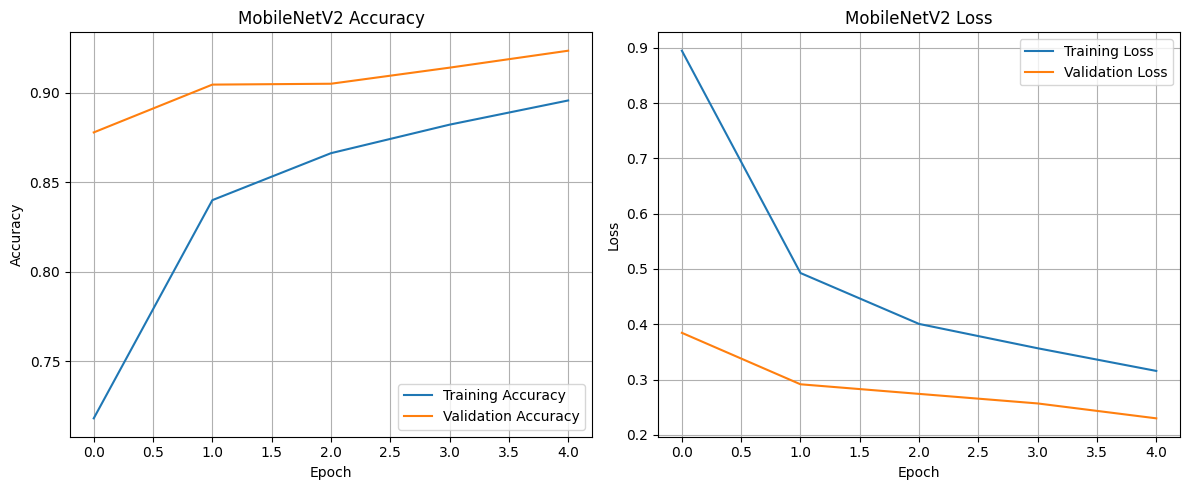

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(mobilenet_history.history["accuracy"], label="Training Accuracy")
plt.plot(mobilenet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(mobilenet_history.history["loss"], label="Training Loss")
plt.plot(mobilenet_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ==========================================
# 1. CNN PREDICTIONS
# ==========================================
val_data.reset()

cnn_probs = cnn_model.predict(val_data, verbose=1)
cnn_y_pred = np.argmax(cnn_probs, axis=1)
cnn_y_true = val_data.classes


# ==========================================
# 2. RESNET50 PREDICTIONS
# ==========================================
resnet_val_data.reset()

resnet_probs = resnet_model.predict(resnet_val_data, verbose=1)
resnet_y_pred = np.argmax(resnet_probs, axis=1)
resnet_y_true = resnet_val_data.classes


# ==========================================
# 3. MOBILENETV2 PREDICTIONS
# ==========================================
mobilenet_val_data.reset()

mobilenet_probs = mobilenet_model.predict(mobilenet_val_data, verbose=1)
mobilenet_y_pred = np.argmax(mobilenet_probs, axis=1)
mobilenet_y_true = mobilenet_val_data.classes


# ==========================================
# 4. FUNCTION TO CALCULATE METRICS
# ==========================================
def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return accuracy, precision, recall, f1


# ==========================================
# 5. CALCULATE ALL MODEL METRICS
# ==========================================
cnn_accuracy, cnn_precision, cnn_recall, cnn_f1 = calculate_metrics(
    cnn_y_true,
    cnn_y_pred
)

resnet_accuracy, resnet_precision, resnet_recall, resnet_f1 = calculate_metrics(
    resnet_y_true,
    resnet_y_pred
)

mobilenet_accuracy, mobilenet_precision, mobilenet_recall, mobilenet_f1 = calculate_metrics(
    mobilenet_y_true,
    mobilenet_y_pred
)


# ==========================================
# 6. COMPARISON TABLE
# ==========================================
comparison = pd.DataFrame({

    "Model": [
        "Basic CNN",
        "ResNet50",
        "MobileNetV2"
    ],

    "Accuracy": [
        cnn_accuracy,
        resnet_accuracy,
        mobilenet_accuracy
    ],

    "Precision": [
        cnn_precision,
        resnet_precision,
        mobilenet_precision
    ],

    "Recall": [
        cnn_recall,
        resnet_recall,
        mobilenet_recall
    ],

    "F1 Score": [
        cnn_f1,
        resnet_f1,
        mobilenet_f1
    ],

    "Parameters": [
        cnn_model.count_params(),
        resnet_model.count_params(),
        mobilenet_model.count_params()
    ]
})


# ==========================================
# 7. ROUND VALUES
# ==========================================
comparison["Accuracy"] = comparison["Accuracy"].round(4)
comparison["Precision"] = comparison["Precision"].round(4)
comparison["Recall"] = comparison["Recall"].round(4)
comparison["F1 Score"] = comparison["F1 Score"].round(4)


# ==========================================
# 8. DISPLAY
# ==========================================
print("===== MODEL COMPARISON =====")

display(comparison)

129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step
129/129 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step
129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step
===== MODEL COMPARISON =====


,Model,Accuracy,Precision,Recall,F1 Score,Parameters
0,Basic CNN,0.9042,0.9069,0.9042,0.9023,11170895
1,ResNet50,0.9624,0.9631,0.9624,0.9617,23851919
2,MobileNetV2,0.9233,0.9242,0.9233,0.9227,2423887


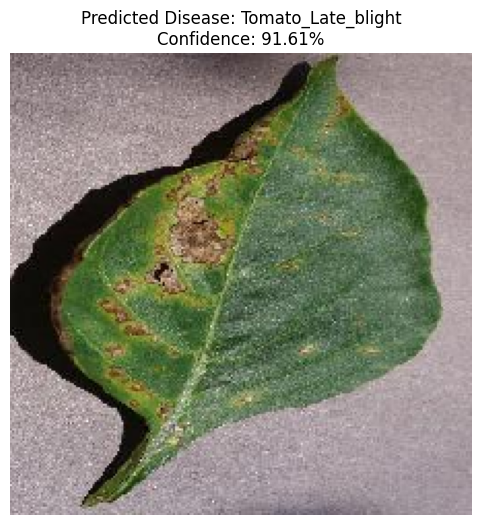

Predicted Disease : Tomato_Late_blight
Confidence        : 91.61%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# ==========================================
# SELECT A SAMPLE IMAGE FROM VALIDATION SET
# ==========================================

sample_path = val_data.filepaths[0]

# Load image
img = image.load_img(sample_path, target_size=(224, 224))

# Convert image to array
img_array = image.img_to_array(img)

# ResNet50 preprocessing
img_input = np.expand_dims(img_array, axis=0)
img_input = preprocess_input(img_input)

# ==========================================
# PREDICT USING RESNET50
# ==========================================

prediction = resnet_model.predict(img_input, verbose=0)

predicted_class = np.argmax(prediction[0])
confidence = prediction[0][predicted_class] * 100

class_names = list(val_data.class_indices.keys())

predicted_disease = class_names[predicted_class]

# ==========================================
# DISPLAY RESULT
# ==========================================

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted Disease: {predicted_disease}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted Disease :", predicted_disease)
print("Confidence        :", f"{confidence:.2f}%")

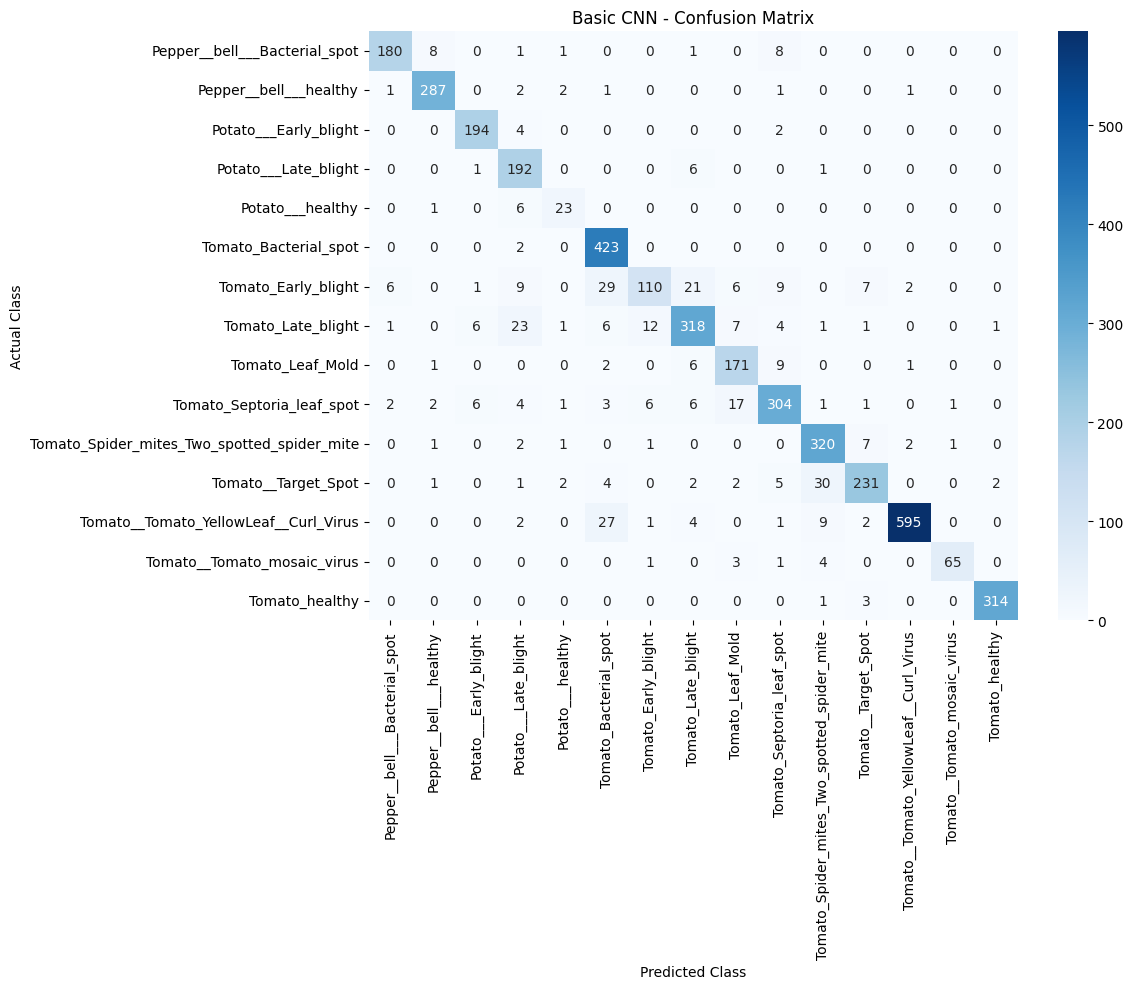

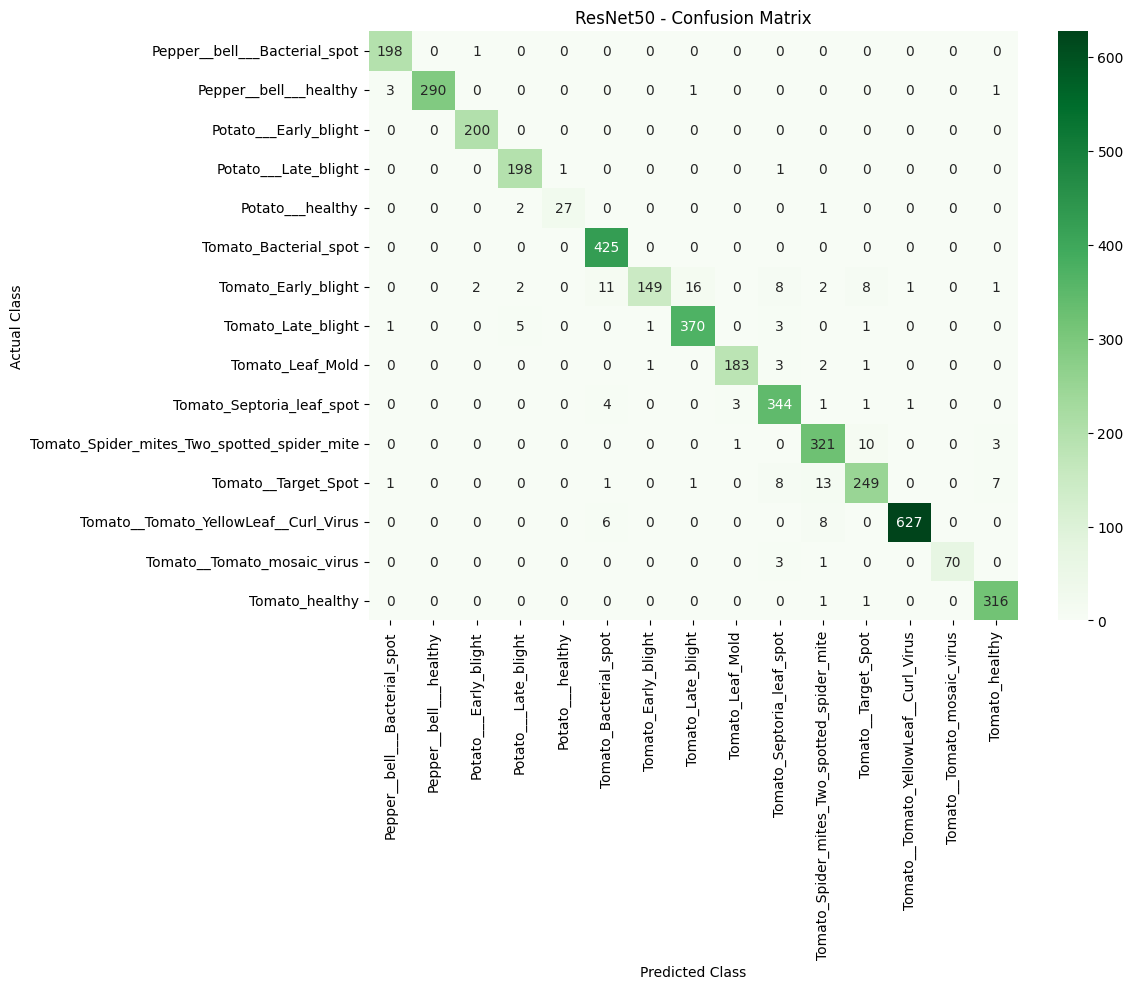

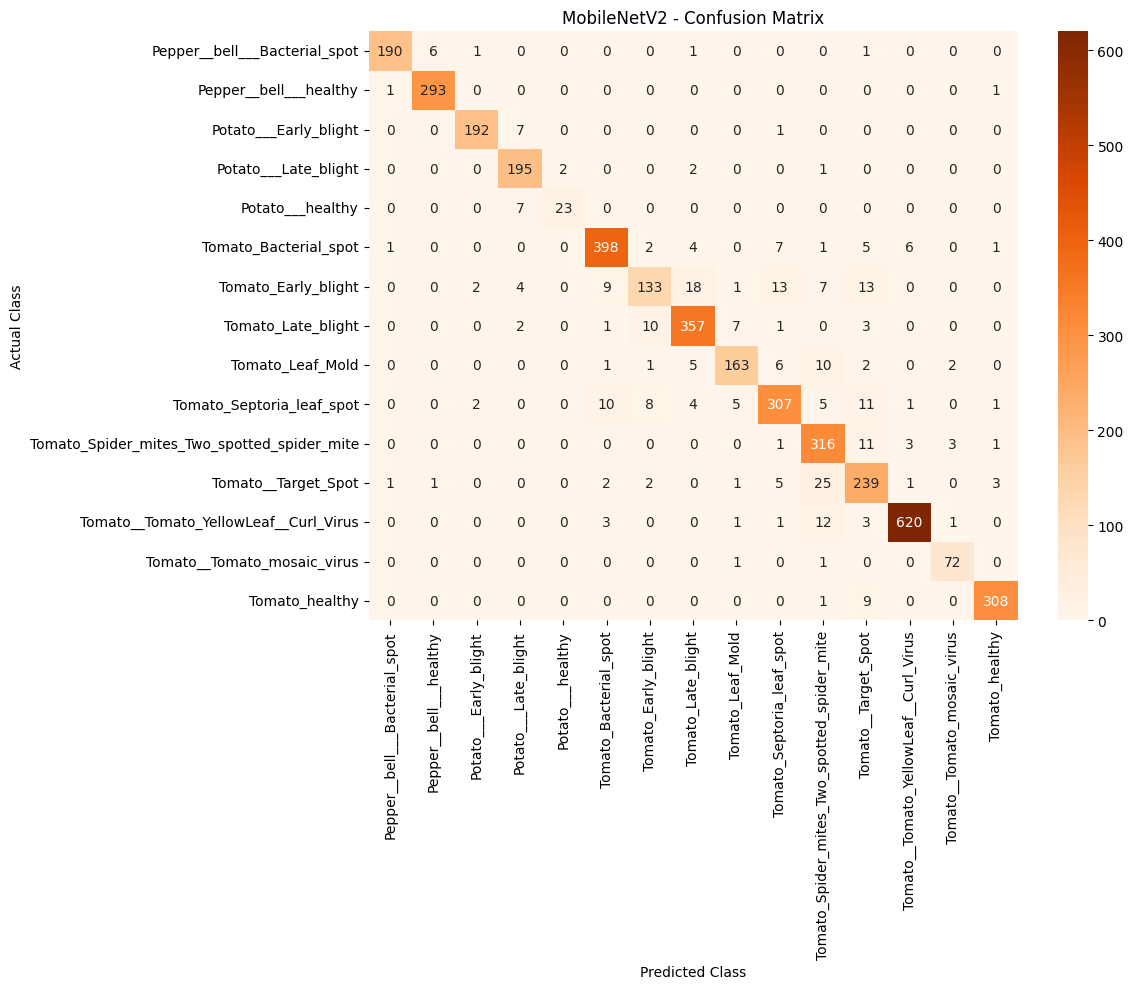

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Class names
class_names = list(val_data.class_indices.keys())

# Create confusion matrices
cnn_cm = confusion_matrix(cnn_y_true, cnn_y_pred)
resnet_cm = confusion_matrix(resnet_y_true, resnet_y_pred)
mobilenet_cm = confusion_matrix(mobilenet_y_true, mobilenet_y_pred)

# =========================
# CNN
# =========================
plt.figure(figsize=(12, 10))
sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Basic CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# =========================
# RESNET50
# =========================
plt.figure(figsize=(12, 10))
sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("ResNet50 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# =========================
# MOBILENETV2
# =========================
plt.figure(figsize=(12, 10))
sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Example leaf:
/kaggle/input/plantdisease/PlantVillage/Tomato_Late_blight/06c6a302-ae34-4d38-9e4b-3a6acdd42d91___GHLB2 Leaf 9047.JPG


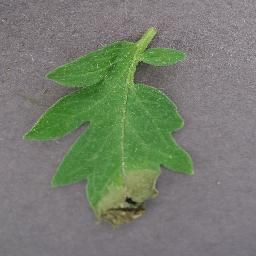

In [ ]:
import os
import random
from IPython.display import display
from PIL import Image

folder = "/kaggle/input/plantdisease/PlantVillage/Tomato_Late_blight"

files = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample = random.choice(files)
sample_path = os.path.join(folder, sample)

print("Example leaf:")
print(sample_path)

display(Image.open(sample_path))

In [ ]:
!pip install -q kagglehub

import kagglehub
import os

# Download/access PlantVillage dataset
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Dataset location:")
print(path)

print("\nContents:")
print(os.listdir(path))

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset location:
/kaggle/input/plantdisease

Contents:
['PlantVillage', 'plantvillage']


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import time

# ==========================================
# SETTINGS
# ==========================================
dataset_path = "/kaggle/input/plantdisease/PlantVillage"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 15

# ==========================================
# DATA GENERATORS
# ==========================================
resnet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

resnet_train_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

resnet_val_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

# ==========================================
# RESNET50 MODEL
# ==========================================
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

resnet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# ==========================================
# COMPILE
# ==========================================
resnet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# TRAIN
# ==========================================
print("Training ResNet50...")

start_time = time.time()

history_resnet = resnet_model.fit(
    resnet_train_data,
    validation_data=resnet_val_data,
    epochs=5
)

resnet_training_time = time.time() - start_time

print("\nTraining completed!")
print("Training time:", round(resnet_training_time, 2), "seconds")

# ==========================================
# SAVE MODEL
# ==========================================
resnet_model.save("/content/resnet50_plant_disease.keras")

print("\nModel saved successfully!")
print("/content/resnet50_plant_disease.keras")

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training ResNet50...
Epoch 1/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 145s 255ms/step - accuracy: 0.7594 - loss: 0.7718 - val_accuracy: 0.9335 - val_loss: 0.2333
Epoch 2/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 77s 149ms/step - accuracy: 0.8820 - loss: 0.3586 - val_accuracy: 0.9413 - val_loss: 0.1769
Epoch 3/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 77s 148ms/step - accuracy: 0.9042 - loss: 0.2851 - val_accuracy: 0.9537 - val_loss: 0.1404
Epoch 4/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 77s 148ms/step - accuracy: 0.9206 - loss: 0.2355 - val_accuracy: 0.9605 - val_loss: 0.1200
Epoch 5/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 77s 149ms/step - accuracy: 0.9331 - loss: 0.1984 - val_accuracy: 0.9672 - val_loss: 0.0997

Training completed!
Training time: 453.35 seconds

Model saved successfully!
/content/resnet50_plant_disease.keras


In [ ]:
import os
import shutil
from google.colab import files

# Dataset location
dataset_path = "/kaggle/input/plantdisease/PlantVillage"

# Classes we want
sample_classes = [
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Potato___Early_blight",
    "Pepper__bell___Bacterial_spot"
]

# Folder for sample images
sample_folder = "/content/sample_leaf_images"

os.makedirs(sample_folder, exist_ok=True)

# Copy one image from each class
for class_name in sample_classes:

    source_folder = os.path.join(
        dataset_path,
        class_name
    )

    image_files = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    source_file = os.path.join(
        source_folder,
        image_files[0]
    )

    destination_file = os.path.join(
        sample_folder,
        class_name + ".jpg"
    )

    shutil.copy(
        source_file,
        destination_file
    )

# Create ZIP
zip_path = shutil.make_archive(
    "/content/sample_leaf_images",
    "zip",
    sample_folder
)

print("4 sample images created successfully!")
print(zip_path)

# Download ZIP
files.download(zip_path)

4 sample images created successfully!
/content/sample_leaf_images.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Using original saved ResNet50 model

Select one or more leaf images:


Saving Tomato_Early_blight.jpg to Tomato_Early_blight (1).jpg
Saving Pepper__bell___Bacterial_spot.jpg to Pepper__bell___Bacterial_spot.jpg
Saving Potato___Early_blight.jpg to Potato___Early_blight.jpg


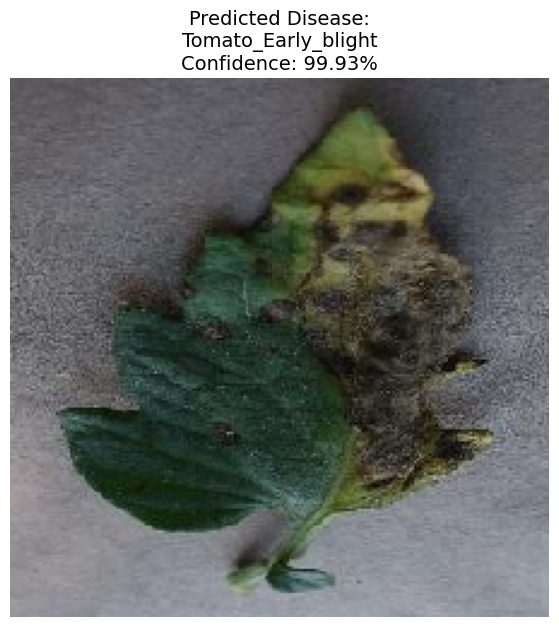


           PLANT DISEASE PREDICTION
Image              : Tomato_Early_blight (1).jpg
Predicted Disease  : Tomato_Early_blight
Confidence         : 99.93%

Top 3 Predictions:
1. Tomato_Early_blight  →  99.93%
2. Tomato_Bacterial_spot  →  0.05%
3. Tomato_Late_blight  →  0.02%


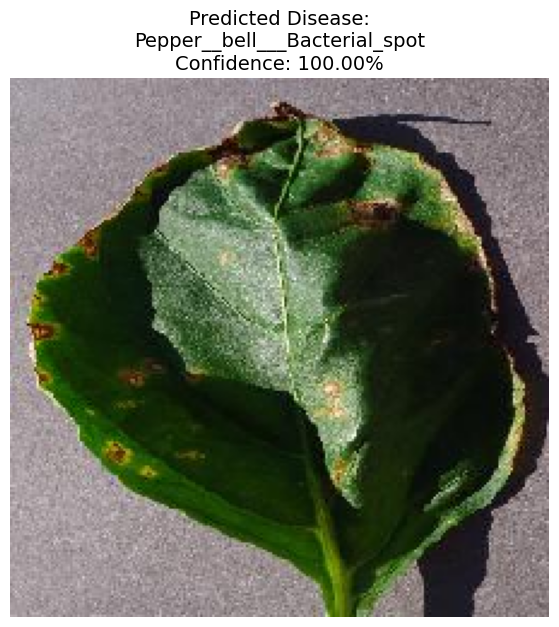


           PLANT DISEASE PREDICTION
Image              : Pepper__bell___Bacterial_spot.jpg
Predicted Disease  : Pepper__bell___Bacterial_spot
Confidence         : 100.00%

Top 3 Predictions:
1. Pepper__bell___Bacterial_spot  →  100.00%
2. Tomato_Early_blight  →  0.00%
3. Pepper__bell___healthy  →  0.00%


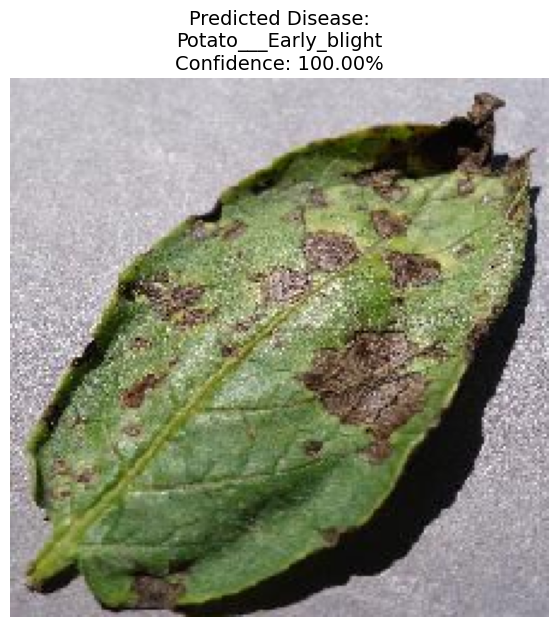


           PLANT DISEASE PREDICTION
Image              : Potato___Early_blight.jpg
Predicted Disease  : Potato___Early_blight
Confidence         : 100.00%

Top 3 Predictions:
1. Potato___Early_blight  →  100.00%
2. Tomato_Early_blight  →  0.00%
3. Tomato_Septoria_leaf_spot  →  0.00%


In [ ]:
# ============================================
# PLANT DISEASE DETECTION - FINAL DEMO
# Upload one or multiple leaf images
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input


# ============================================
# 1. CLASS NAMES
# ============================================

class_names = [
    "Pepper__bell___Bacterial_spot",
    "Pepper__bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Septoria_leaf_spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite",
    "Tomato__Target_Spot",
    "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "Tomato__Tomato_mosaic_virus",
    "Tomato_healthy"
]


# ============================================
# 2. LOAD BEST AVAILABLE MODEL
# ============================================

fine_tuned_path = "/content/resnet50_plant_disease_finetuned.keras"
original_path = "/content/resnet50_plant_disease.keras"

if os.path.exists(fine_tuned_path):

    model = tf.keras.models.load_model(fine_tuned_path)
    print("Using fine-tuned ResNet50 model")

elif os.path.exists(original_path):

    model = tf.keras.models.load_model(original_path)
    print("Using original saved ResNet50 model")

elif "resnet_model" in globals():

    model = resnet_model
    print("Using ResNet50 model currently in memory")

else:

    raise FileNotFoundError(
        "No trained ResNet50 model found. "
        "Please train/save the model first."
    )


# ============================================
# 3. UPLOAD IMAGES
# ============================================

print("\nSelect one or more leaf images:")

uploaded = files.upload()


# ============================================
# 4. PREDICT EACH IMAGE
# ============================================

for file_name in uploaded.keys():

    # Load image
    img = image.load_img(
        file_name,
        target_size=(224, 224)
    )

    # Convert to array
    img_array = image.img_to_array(img)

    # Add batch dimension
    img_input = np.expand_dims(
        img_array,
        axis=0
    )

    # ResNet50 preprocessing
    img_input = preprocess_input(img_input)

    # Prediction
    prediction = model.predict(
        img_input,
        verbose=0
    )[0]

    # Top prediction
    predicted_index = np.argmax(prediction)

    predicted_class = class_names[predicted_index]

    confidence = prediction[predicted_index] * 100


    # ========================================
    # TOP 3 PREDICTIONS
    # ========================================

    top3_indices = np.argsort(prediction)[-3:][::-1]


    # ========================================
    # DISPLAY IMAGE
    # ========================================

    plt.figure(figsize=(8, 7))

    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"Predicted Disease:\n"
        f"{predicted_class}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=14
    )

    plt.show()


    # ========================================
    # PRINT RESULT
    # ========================================

    print("\n" + "=" * 55)
    print("           PLANT DISEASE PREDICTION")
    print("=" * 55)

    print("Image              :", file_name)

    print(
        "Predicted Disease  :",
        predicted_class
    )

    print(
        "Confidence         :",
        f"{confidence:.2f}%"
    )

    print("\nTop 3 Predictions:")

    for rank, index in enumerate(top3_indices, 1):

        print(
            f"{rank}. {class_names[index]}"
            f"  →  {prediction[index] * 100:.2f}%"
        )

    print("=" * 55)

In [ ]:
!pip install -q gradio matplotlib pillow pandas

In [ ]:
import os

print("Checking for saved model files...\n")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

Checking for saved model files...



In [ ]:
!pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download("emmarex/plantdisease")

print("Dataset location:", path)
print("Contents:", os.listdir(path))

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset location: /kaggle/input/plantdisease
Contents: ['PlantVillage', 'plantvillage']


In [ ]:
import tensorflow as tf
import time
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

# ============================================================
# SETTINGS
# ============================================================

dataset_path = "/kaggle/input/plantdisease/PlantVillage"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 15

# ============================================================
# DATA GENERATORS
# ============================================================

resnet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

resnet_train_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

resnet_val_data = resnet_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

print("\nClasses:", resnet_train_data.class_indices)

# ============================================================
# RESNET50 MODEL
# ============================================================

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

resnet_model = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

# ============================================================
# COMPILE
# ============================================================

resnet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ============================================================
# MODEL SUMMARY
# ============================================================

resnet_model.summary()

# ============================================================
# TRAIN
# ============================================================

print("\n🚀 Starting ResNet50 training...")

start_time = time.time()

history_resnet = resnet_model.fit(
    resnet_train_data,
    validation_data=resnet_val_data,
    epochs=5
)

training_time = time.time() - start_time

print("\n======================================")
print("✅ TRAINING COMPLETED")
print("======================================")
print(f"Training time: {training_time:.2f} seconds")

# ============================================================
# SAVE MODEL
# ============================================================

model_path = "/content/resnet50_plant_disease.keras"

resnet_model.save(model_path)

print("\n✅ Model saved successfully!")
print("📁", model_path)

# ============================================================
# FINAL VALIDATION ACCURACY
# ============================================================

final_accuracy = history_resnet.history["val_accuracy"][-1]

print(f"\n🎯 Final Validation Accuracy: {final_accuracy * 100:.2f}%")

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.

Classes: {'Pepper__bell___Bacterial_spot': 0, 'Pepper__bell___healthy': 1, 'Potato___Early_blight': 2, 'Potato___Late_blight': 3, 'Potato___healthy': 4, 'Tomato_Bacterial_spot': 5, 'Tomato_Early_blight': 6, 'Tomato_Late_blight': 7, 'Tomato_Leaf_Mold': 8, 'Tomato_Septoria_leaf_spot': 9, 'Tomato_Spider_mites_Two_spotted_spider_mite': 10, 'Tomato__Target_Spot': 11, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 12, 'Tomato__Tomato_mosaic_virus': 13, 'Tomato_healthy': 14}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,919 (90.99 MB)

 Trainable params: 264,207 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


🚀 Starting ResNet50 training...
Epoch 1/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 201s 357ms/step - accuracy: 0.7520 - loss: 0.7790 - val_accuracy: 0.9296 - val_loss: 0.2419
Epoch 2/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 98s 189ms/step - accuracy: 0.8813 - loss: 0.3637 - val_accuracy: 0.9374 - val_loss: 0.1898
Epoch 3/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 90s 174ms/step - accuracy: 0.9041 - loss: 0.2849 - val_accuracy: 0.9549 - val_loss: 0.1432
Epoch 4/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 97s 187ms/step - accuracy: 0.9174 - loss: 0.2468 - val_accuracy: 0.9629 - val_loss: 0.1175
Epoch 5/5
517/517 ━━━━━━━━━━━━━━━━━━━━ 97s 188ms/step - accuracy: 0.9279 - loss: 0.2130 - val_accuracy: 0.9643 - val_loss: 0.1080

✅ TRAINING COMPLETED
Training time: 583.56 seconds

✅ Model saved successfully!
📁 /content/resnet50_plant_disease.keras

🎯 Final Validation Accuracy: 96.43%


In [14]:
import gradio as gr
import tensorflow as tf
import numpy as np
import pandas as pd
from PIL import Image
from tensorflow.keras.applications.resnet50 import preprocess_input

# ============================================================
# LOAD SAVED MODEL
# ============================================================

model_path = "/content/resnet50_plant_disease.keras"

resnet_model = tf.keras.models.load_model(model_path)

print("✅ ResNet50 model loaded successfully!")

# ============================================================
# CLASS NAMES
# ============================================================

class_names = [
    "Pepper__bell___Bacterial_spot",
    "Pepper__bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Septoria_leaf_spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite",
    "Tomato__Target_Spot",
    "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "Tomato__Tomato_mosaic_virus",
    "Tomato_healthy"
]

def clean_name(name):
    return name.replace("___", " - ").replace("__", " ").replace("_", " ")

# ============================================================
# DISEASE INFORMATION
# ============================================================

disease_info = {
    "Pepper__bell___Bacterial_spot":
        ("Pepper", "Disease",
         "Small dark spots may appear on leaves and fruits.",
         "Maintain good sanitation and remove severely affected material."),

    "Pepper__bell___healthy":
        ("Pepper", "Healthy",
         "No major visible disease symptoms detected.",
         "Continue regular monitoring and proper plant care."),

    "Potato___Early_blight":
        ("Potato", "Disease",
         "Dark circular or target-like lesions may develop on older leaves.",
         "Maintain crop sanitation and monitor affected foliage."),

    "Potato___Late_blight":
        ("Potato", "Disease",
         "Dark irregular lesions can develop rapidly on leaves.",
         "Monitor plants carefully and follow suitable disease-management practices."),

    "Potato___healthy":
        ("Potato", "Healthy",
         "No major visible disease symptoms detected.",
         "Continue regular monitoring and crop care."),

    "Tomato_Bacterial_spot":
        ("Tomato", "Disease",
         "Small dark lesions may occur on leaves and fruits.",
         "Use good sanitation and avoid unnecessary leaf wetness."),

    "Tomato_Early_blight":
        ("Tomato", "Disease",
         "Brown target-like spots commonly develop on older leaves.",
         "Remove affected material and maintain good crop sanitation."),

    "Tomato_Late_blight":
        ("Tomato", "Disease",
         "Dark irregular lesions can spread under favorable conditions.",
         "Monitor plants frequently and follow suitable management practices."),

    "Tomato_Leaf_Mold":
        ("Tomato", "Disease",
         "Yellowish patches and mold growth may occur on leaves.",
         "Improve air circulation and reduce excessive humidity."),

    "Tomato_Septoria_leaf_spot":
        ("Tomato", "Disease",
         "Small circular leaf spots may develop.",
         "Remove affected foliage and maintain good sanitation."),

    "Tomato_Spider_mites_Two_spotted_spider_mite":
        ("Tomato", "Pest",
         "Fine webbing and speckled leaves may occur.",
         "Inspect plants regularly and follow suitable pest-management practices."),

    "Tomato__Target_Spot":
        ("Tomato", "Disease",
         "Circular target-like lesions may develop on leaves.",
         "Remove severely affected material and maintain sanitation."),

    "Tomato__Tomato_YellowLeaf__Curl_Virus":
        ("Tomato", "Disease",
         "Leaves may curl and show yellowing.",
         "Monitor plants and insect vectors carefully."),

    "Tomato__Tomato_mosaic_virus":
        ("Tomato", "Disease",
         "Mottled or mosaic-like patterns may appear on leaves.",
         "Maintain sanitation and avoid spreading affected plant material."),

    "Tomato_healthy":
        ("Tomato", "Healthy",
         "No major visible disease symptoms detected.",
         "Continue regular monitoring and proper plant care.")
}

# ============================================================
# PREDICTION
# ============================================================

def predict_leaf(image):

    if image is None:
        return (
            "⚠️ Please upload a leaf image.",
            "",
            pd.DataFrame(),
            ""
        )

    img = Image.fromarray(image.astype("uint8")).convert("RGB")
    img = img.resize((224, 224))

    arr = np.array(img).astype(np.float32)
    arr = preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    predictions = resnet_model.predict(arr, verbose=0)[0]

    top_indices = np.argsort(predictions)[::-1][:3]

    best_index = top_indices[0]
    best_class = class_names[best_index]
    confidence = predictions[best_index] * 100

    plant, status, symptoms, management = disease_info[best_class]

    result = f"""
# 🔍 Prediction Result

### 🌿 {clean_name(best_class)}

**Plant:** {plant}

**Status:** {status}

**Confidence:** {confidence:.2f}%
"""

    if confidence < 60:
        warning = """
⚠️ **LOW CONFIDENCE**

The model is uncertain about this prediction.

Try:
- A clearer image
- Better lighting
- A close-up leaf image
- A plain background
"""
    elif confidence < 80:
        warning = "🟡 **MODERATE CONFIDENCE** — Check the Top-3 predictions."
    else:
        warning = "🟢 **HIGH CONFIDENCE** — Strong model prediction."

    top3 = []

    for index in top_indices:
        top3.append([
            clean_name(class_names[index]),
            f"{predictions[index] * 100:.2f}%"
        ])

    top3_df = pd.DataFrame(
        top3,
        columns=["Prediction", "Confidence"]
    )

    details = f"""
# 📚 Disease Information

**Plant:** {plant}

**Condition:** {status}

### Symptoms
{symptoms}

### General Management
{management}

> This information is for educational purposes. Field diagnosis should be confirmed by an agricultural professional.
"""

    return result, warning, top3_df, details


# ============================================================
# MODEL COMPARISON
# ============================================================

comparison_df = pd.DataFrame({
    "Model": [
        "Basic CNN",
        "ResNet50",
        "MobileNetV2"
    ],
    "Accuracy": [
        "90.42%",
        "96.72%",
        "92.33%"
    ],
    "Precision": [
        "90.69%",
        "96.31%",
        "92.42%"
    ],
    "Recall": [
        "90.42%",
        "96.24%",
        "92.33%"
    ],
    "F1 Score": [
        "90.23%",
        "96.17%",
        "92.27%"
    ],
    "Parameters": [
        "11,170,895",
        "23,851,919",
        "2,423,887"
    ]
})


# ============================================================
# HOME
# ============================================================

home = """
# 🌿 Plant Disease Detection System

## AI-Powered Plant Health Analysis

This application uses **Deep Learning and Transfer Learning**
to classify plant leaf diseases.

### 🧠 Models Compared

- Basic CNN
- ResNet50
- MobileNetV2

### ⭐ Features

✅ Disease prediction
✅ Confidence score
✅ Top-3 predictions
✅ Low-confidence warning
✅ Disease information
✅ Model comparison
✅ 15 supported classes

### 🏆 Best Recorded Model

**ResNet50**

Recorded validation accuracy: **96.72%**
"""


# ============================================================
# ABOUT
# ============================================================

about = """
# ℹ️ About Project

## Project Title

**Plant Disease Detection Using CNN and Transfer Learning:
A Comparative Study**

### Dataset

PlantVillage

### Supported Classes

**15**

### Technologies

- Python
- TensorFlow
- Keras
- CNN
- ResNet50
- MobileNetV2
- NumPy
- Pandas
- Gradio

### Project Workflow

**Leaf Image → Preprocessing → ResNet50 → Prediction → Confidence → Top-3 Results**

### Main Contribution

The project compares multiple deep-learning models using
accuracy, precision, recall and F1-score and provides
a user-friendly prediction interface.
"""


# ============================================================
# MULTI-PAGE APPLICATION
# ============================================================

with gr.Blocks(
    title="Plant Disease Detection"
) as app:

    gr.Markdown(
        """
        # 🌿 PLANT DISEASE DETECTION
        ### Deep Learning Based Plant Health Analysis
        """
    )

    # --------------------------------------------------------
    # PAGE 1
    # --------------------------------------------------------

    with gr.Tab("🏠 Home"):

        gr.Markdown(home)

    # --------------------------------------------------------
    # PAGE 2
    # --------------------------------------------------------

    with gr.Tab("🔍 Disease Prediction"):

        gr.Markdown(
            "## Upload a clear image of a plant leaf"
        )

        with gr.Row():

            with gr.Column():

                image_input = gr.Image(
                    type="numpy",
                    label="📷 Upload Leaf"
                )

                predict_btn = gr.Button(
                    "🔍 ANALYZE LEAF",
                    variant="primary"
                )

            with gr.Column():

                result_output = gr.Markdown()

                warning_output = gr.Markdown()

        gr.Markdown("## 🔝 Top-3 Predictions")

        top3_output = gr.Dataframe(
            headers=["Prediction", "Confidence"],
            interactive=False
        )

        gr.Markdown("## 📚 Disease Information")

        disease_output = gr.Markdown()

        predict_btn.click(
            predict_leaf,
            inputs=image_input,
            outputs=[
                result_output,
                warning_output,
                top3_output,
                disease_output
            ]
        )

    # --------------------------------------------------------
    # PAGE 3
    # --------------------------------------------------------

    with gr.Tab("📊 Model Comparison"):

        gr.Markdown(
            """
            # 📊 Model Performance Comparison

            Three models were evaluated under the project conditions.
            """
        )

        gr.Dataframe(
            value=comparison_df,
            interactive=False
        )

        gr.Markdown(
            """
            ### 🏆 Highest Recorded Accuracy

            **ResNet50 — 96.72%**

            ResNet50 achieved the highest recorded validation
            accuracy among the three models.
            """
        )

    # --------------------------------------------------------
    # PAGE 4
    # --------------------------------------------------------

    with gr.Tab("📚 Disease Classes"):

        class_table = []

        for name in class_names:

            plant, status, symptoms, management = disease_info[name]

            class_table.append([
                clean_name(name),
                plant,
                status
            ])

        classes_df = pd.DataFrame(
            class_table,
            columns=[
                "Disease / Class",
                "Plant",
                "Type"
            ]
        )

        gr.Markdown(
            "# 📚 Supported Disease Classes"
        )

        gr.Markdown(
            "The model currently supports **15 PlantVillage classes**."
        )

        gr.Dataframe(
            value=classes_df,
            interactive=False
        )

    # --------------------------------------------------------
    # PAGE 5
    # --------------------------------------------------------

    with gr.Tab("ℹ️ About"):

        gr.Markdown(about)

    gr.Markdown(
        """
        ---
        🌱 **Plant Disease Detection System**
        | CNN + ResNet50 + MobileNetV2 | PlantVillage
        """
    )


# ============================================================
# START APPLICATION
# ============================================================

app.launch(
    share=True
)

✅ ResNet50 model loaded successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://39c1d273285d15ace8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
from google.colab import files

uploaded = files.upload()

Saving resnet50_plant_disease.keras to resnet50_plant_disease.keras


In [13]:
import tensorflow as tf

model_path = "/content/resnet50_plant_disease.keras"

resnet_model = tf.keras.models.load_model(model_path)

print("✅ ResNet50 model loaded successfully!")

✅ ResNet50 model loaded successfully!
